# Assessment Notebook

In [ ]:
# pandas helps to construct dataframes/arrays
import pandas as pd
# numpy performs various mathematical operations with arrays 
import numpy as np
# pyplot from the matplotlib library helps for plotting graphs etc
import matplotlib.pyplot as plt

# scipy for scientific computing, in particular for calcuting the R-squared..
import scipy as sp

# seaborn - which is similar to matplotlib - great for pairplots
import seaborn as sns

# Mathematical functions from the standard library.
# https://docs.python.org/3/library/math.html
import math

# Permutations and combinations.
# https://docs.python.org/3/library/itertools.html
import itertools
    
# Random selections.
# https://docs.python.org/3/library/random.html
import random

From reading the description of the data [here](https://archive.ics.uci.edu/dataset/53/iris),  that there are 150 instances. Each instance has recorded four features (sepal width, sepal length, petal width, and petal length) and one class attribute. According to UC Irvine, the dataset contains 3 classes (setosa, versicolour, and virginica), with  each class having 50 instances. 

Therefore, the data contains 5 columns, the 4 features (sepal_length, sepal_width, petal_length, petal_width), and finally the species/class of iris. 

Let's create an array with those names which we will then append to the top of the raw data that we pull in from the text file from UC Irvine.

In [2]:
# the name of the five columns in the dataset
col_names= ("sepal_length",
    "sepal_width", 
    "petal_length", 
    "petal_width", 
    "class", 
)

#Load the iris dataset into as a dataframe using the Pandas library.
iris_df = pd.read_csv ("https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv", sep=',', header=0, names=col_names)
iris_df.head()

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Confirm three are three unique species
print(f"There are {iris_df['class'].nunique()} classes of iris in the dataset\n")

# Use "drop na" to remove any observations in the series that have no value
iris_df.dropna(inplace=True)

# Show the data again to see if there was any change, that is rows removed
print(f"{iris_df}") 


There are 3 classes of iris in the dataset

     sepal_length  sepal_width  petal_length  petal_width      class
0             5.1          3.5           1.4          0.2     setosa
1             4.9          3.0           1.4          0.2     setosa
2             4.7          3.2           1.3          0.2     setosa
3             4.6          3.1           1.5          0.2     setosa
4             5.0          3.6           1.4          0.2     setosa
..            ...          ...           ...          ...        ...
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica

[150 rows x 5 columns]


## Problem 1: Exploring Petal Length

#### 1. Plotting histogram showing how the petal lengths of all 150 flowers, with a superimposed normal distribution curve, using the mean and standard deviation calculated from the data

In [9]:
mean_petal_length = np.mean(iris_df["petal_length"]) 
# calculate the mean of the petal lengths
std_deviation_petal_length = np.std(iris_df["petal_length"], ddof=1) 
# calculate the standard deviation of the petal lengths, using degreee of freedom = 1 to get the sample standard deviation

print(f"Mean petal length of all flowers: {round(mean_petal_length,2)}")
print(f"Standard deviation of petal length for all flowers: {round(std_deviation_petal_length,2)}")

Mean petal length of all flowers: 3.76
Standard deviation of petal length for all flowers: 1.76


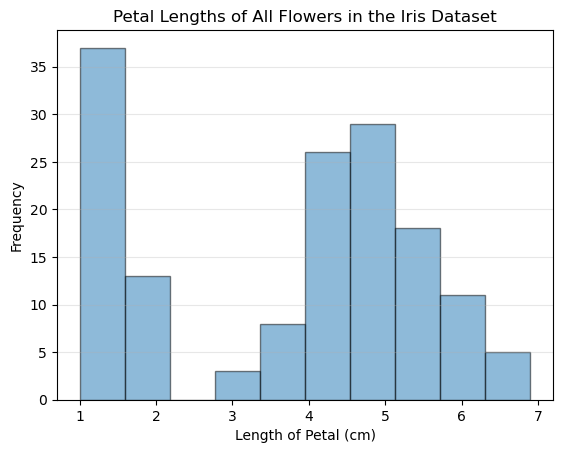

In [14]:
fig, ax = plt.subplots()

ax.hist(iris_df["petal_length"], bins=10, edgecolor="black", alpha=0.5, density=False, label="Petal Lengths Histogram")
# I am plotting a histogram using data from the petal length column of the array, 
# spreading the data over 10 bins (8 was too few and 12 too many), 
# black edges on each bar, 50% transparency, and normalized to form a probability density.


# Dictating the look of my chart
# legend
#ax.legend(loc="upper right")

# axis titles
ax.set_xlabel("Length of Petal (cm)")
ax.set_ylabel("Frequency")

# chart title
plt.title("Petal Lengths of All Flowers in the Iris Dataset")

plt.grid(axis="y", alpha=0.3)
plt.show()
#plt.savefig("petal_lengths.png")

This chart would indicate that there is wide disparity between the flowers. There are three classes of iris with 50 flowers in each class. Therefore, I would assume from the chart that the first two bars (showing a petal length of about 2 centimeters and lower) comprising a frequency of about 50 flowers (~37 in the first and ~13 in the second) are from one flower class because there is a relatively large gap between them and the other bars. I could not deduct with great certainty that the other two classes of iris differ from this histogram in terms of their petal lengths.

### 2. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.

Note: The formula for the normal distribution which I use in my calculations can be found [here](https://statisticsfundamentals.com/normal-distribution/)

$$
f(x) = \frac{1}{\sigma\sqrt{2\pi}} \, e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$
So, I could create the normal distribution using the above formula as follows:

In [16]:
xmin = 1 # I've set the minimum x-axis limit to 1, as there are no negative petal lengths
xmax = 7 # I've set the maximum x-axis limit to 7, as there are no petal lengths greater than 7 in the dataset

# these are the x-axis limits of the histogram plot, I'm going to go with 3 standard deviations from the mean, which should cover 99.7% of a normal distribution 
x = np.linspace(xmin, xmax, 100) #  create an array of 100 evenly spaced values between the minimum and maximum x-axis limits

# calculating the normal distribution values for the x values using the mean and standard deviation of the petal lengths using the formula above
p = (1 / (std_deviation_petal_length * np.sqrt(2 * np.pi))) * np.exp(-((x - mean_petal_length) ** 2) / (2 * std_deviation_petal_length**2))
print(f"Normal distribution values for the x values: {p}")

Normal distribution values for the x values: [0.06660186 0.07023502 0.07397905 0.07783077 0.08178647 0.08584189
 0.08999215 0.09423183 0.09855489 0.10295474 0.10742419 0.1119555
 0.11654037 0.12116995 0.12583489 0.13052534 0.13523097 0.13994104
 0.1446444  0.14932954 0.15398466 0.15859766 0.16315624 0.16764793
 0.17206015 0.17638027 0.18059565 0.18469375 0.18866211 0.19248849
 0.1961609  0.19966766 0.20299746 0.20613943 0.2090832  0.21181895
 0.21433745 0.21663016 0.21868922 0.22050753 0.22207879 0.2233975
 0.22445907 0.22525974 0.22579671 0.22606808 0.22607288 0.2258111
 0.22528367 0.22449244 0.22344021 0.22213067 0.22056842 0.2187589
 0.21670839 0.21442396 0.21191344 0.20918536 0.20624891 0.20311389
 0.19979067 0.19629009 0.19262344 0.18880239 0.18483893 0.1807453
 0.17653392 0.17221735 0.16780822 0.16331918 0.15876279 0.15415153
 0.14949772 0.14481345 0.14011054 0.13540052 0.13069454 0.12600337
 0.12133733 0.11670631 0.11211968 0.10758629 0.10311447 0.09871199
 0.09438605 0.09014326

In [43]:
# Alternatively, I could use the built-in scipy.stats.norm.pdf function to calculate the normal distribution values for the x values 
# using the mean and standard deviation of the petal lengths
p = sp.stats.norm.pdf(x, loc=mean_petal_length, scale=std_deviation_petal_length)
# Scipy's norm.pdf function calculates the probability density function (PDF) of a normal distribution 

# for a given set of x values between xmin and xmax, using the iris' petal length mean (loc), and iris' petal length standard deviation (scale).
print(f"Normal distribution values for the x values:\n {p}")

Normal distribution values for the x values:
 [6.43741327e-002 1.54127315e-001 3.26634291e-001 6.12714114e-001
 1.01734425e+000 1.49517467e+000 1.94504596e+000 2.23965823e+000
 2.28269336e+000 2.05933662e+000 1.64445145e+000 1.16232803e+000
 7.27194036e-001 4.02703913e-001 1.97394631e-001 8.56443591e-002
 3.28909286e-002 1.11806603e-002 3.36412953e-003 8.95966788e-004
 2.11215146e-004 4.40729525e-005 8.14016444e-006 1.33078579e-006
 1.92573743e-007 2.46660686e-008 2.79651234e-009 2.80638655e-010
 2.49282724e-011 1.95997629e-012 1.36402835e-013 8.40252707e-015
 4.58152843e-016 2.21118356e-017 9.44611326e-019 3.57186836e-020
 1.19550579e-021 3.54178233e-023 9.28765327e-025 2.15577814e-026
 4.42910603e-028 8.05456394e-030 1.29652810e-031 1.84729297e-033
 2.32971912e-035 2.60067027e-037 2.56969137e-039 2.24745282e-041
 1.73985936e-043 1.19220694e-045 7.23107880e-048 3.88211579e-050
 1.84479375e-052 7.75963147e-055 2.88900515e-057 9.52071314e-060
 2.77718357e-062 7.17056931e-065 1.63876482e

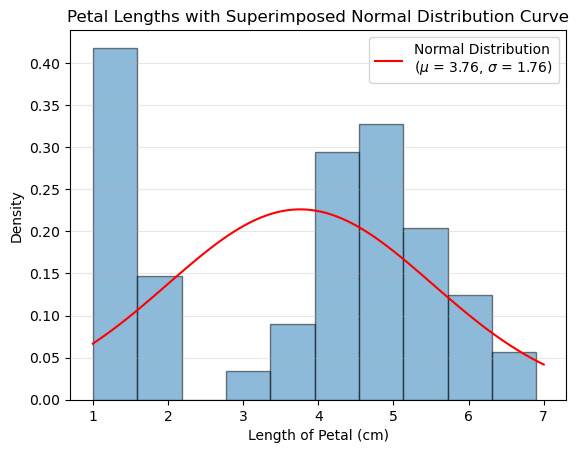

In [ ]:
# Now, i will plot the histogram of the petal lengths and superimpose the normal distribution curve on top of it.

fig, ax = plt.subplots()

ax.hist(iris_df["petal_length"], bins=10, edgecolor="black", alpha=0.5, density=True)
# this is my histogram from above, except for the normalization.

plt.plot(x, p, color="red", label=f"Normal Distribution \n($\mu$ = {mean_petal_length:.2f}, $\sigma$ = {std_deviation_petal_length:.2f})")
# this is my normal distribution curve, which I am plotting on top of the histogram. 

# chart details
# legend
ax.legend(loc="upper right")

# axis titles
ax.set_xlabel("Length of Petal (cm)")
ax.set_ylabel("Density")

# chart title
plt.title("Petal Lengths with Superimposed Normal Distribution Curve")

plt.grid(axis="y", alpha=0.3)
plt.show()
#plt.savefig("petal_lengths.png")

### 3. Plotting histograms for each of the three species, and superimposing an appropriate normal distribution on each.

#### Setosa Petal Lengths

In [23]:
mean_petal_length_setosa = np.mean(iris_df["petal_length"][iris_df["class"] == "setosa"])
# calculate the mean of the petal lengths for the setosa species
std_deviation_petal_length_setosa = np.std(iris_df["petal_length"][iris_df["class"] == "setosa"], ddof=1)
# calculate the standard deviation of the petal lengths for the setosa species

print(f"Mean petal length for Setosa: {round(mean_petal_length_setosa, 2)}")
print(f"Standard deviation of petal length for Setosa: {round(std_deviation_petal_length_setosa, 2)}")

Mean petal length for Setosa: 1.46
Standard deviation of petal length for Setosa: 0.17


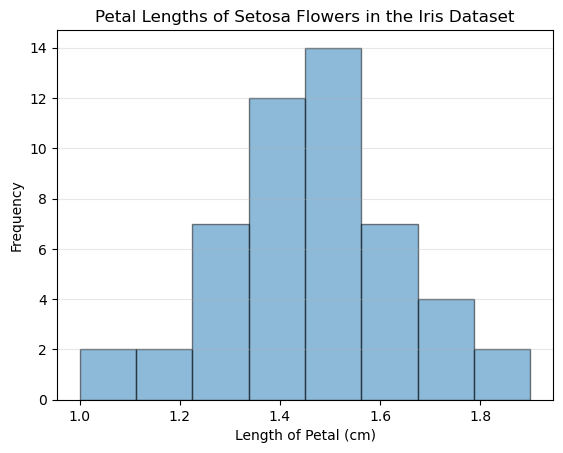

In [ ]:
# I need to find out what my xmin and xmax will be, so I'm going to use the mean and standard deviation of the petal lengths for the setosa species 
# to calculate the x-axis limits of the histogram plot
fig, ax = plt.subplots()
ax.hist(iris_df["petal_length"][iris_df["class"] == "setosa"], bins=8, edgecolor="black", alpha=0.5, density=False, label="Setosa Petal Lengths Histogram")
# Dictating the look of my chart
# legend
#ax.legend(loc="upper right")

# axis titles
ax.set_xlabel("Length of Petal (cm)")
ax.set_ylabel("Frequency")

# chart title
plt.title("Petal Lengths of Setosa Flowers in the Iris Dataset")

plt.grid(axis="y", alpha=0.3)
plt.show()
#plt.savefig("petal_lengths.png")

Given there are 50 setosa flowers, and all 50 fit between the 1 centimeters and 2 centimeters, I can say that indeed, it was the setosa flowers that were in the leftmost part of the chart for the full data set.

In [42]:
# from the histogram, I can see that the petal lengths for the setosa species are spread between 1cm and 2cm, 
# so I will superimpose a normal distribution curve on top of the histogram using a min of 1cm and a max of 2cm.

xmin_setosa = 1 # I've set the minimum x-axis limit to 1, as there are no negative petal lengths
xmax_setosa = 2 # I've set the maximum x-axis limit to 2, as there are no petal lengths greater than 2 in the dataset for the setosa species
x_setosa = np.linspace(xmin_setosa, xmax_setosa, 100)

# To calculate the normal distribution values for the x values 
# using the mean and standard deviation of the petal lengths
p_setosa = sp.stats.norm.pdf(x_setosa, loc=mean_petal_length_setosa, scale=std_deviation_petal_length_setosa)
# Scipy's norm.pdf function calculates the probability density function (PDF) of a normal distribution 

# for a given set of x values between xmin and xmax, using the iris' petal length mean (loc), and iris' petal length standard deviation (scale).
print(f"Normal distribution values for the x values: \n {p_setosa}")

Normal distribution values for the x values: 
 [0.06437413 0.07509062 0.08729475 0.10113902 0.11678244 0.13438924
 0.15412731 0.17616632 0.20067549 0.2278211  0.25776368 0.29065491
 0.32663429 0.36582556 0.40833301 0.45423761 0.5035932  0.55642263
 0.61271411 0.67241772 0.73544225 0.80165253 0.87086718 0.94285704
 1.01734425 1.09400218 1.17245614 1.25228503 1.33302391 1.4141675
 1.49517467 1.57547376 1.6544688  1.73154649 1.80608379 1.87745614
 1.94504596 2.00825151 2.06649568 2.11923475 2.1659668  2.20623968
 2.23965823 2.26589079 2.28467466 2.29582045 2.29921529 2.29482475
 2.28269336 2.26294391 2.23577539 2.20145958 2.16033662 2.11280931
 2.05933662 2.00042627 1.93662672 1.86851873 1.79670658 1.7218092
 1.64445145 1.56525555 1.48483301 1.40377705 1.32265577 1.24200598
 1.16232803 1.08408141 1.00768142 0.93349665 0.86184754 0.79300568
 0.72719404 0.66458799 0.60531694 0.54946665 0.49708197 0.44817007
 0.40270391 0.36062599 0.3218521  0.28627528 0.25376955 0.22419367
 0.19739463 0.173

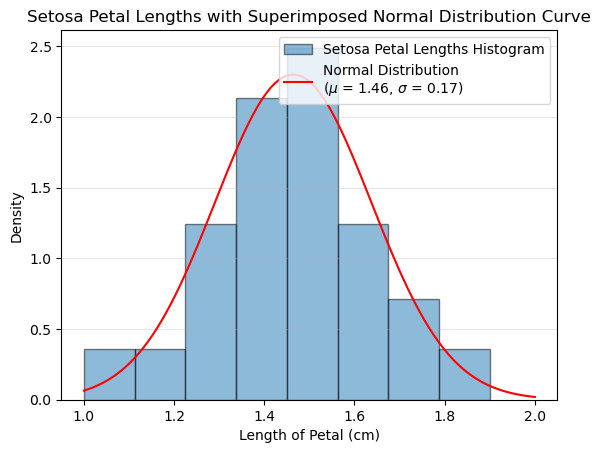

In [44]:
fig, ax = plt.subplots()
ax.hist(iris_df["petal_length"][iris_df["class"] == "setosa"], bins=8, edgecolor="black", alpha=0.5, density=True , label="Setosa Petal Lengths Histogram")
# histogram from above except for the normalization.

p_setosa = (1 / (std_deviation_petal_length_setosa * np.sqrt(2 * np.pi))) * np.exp(-((x_setosa - mean_petal_length_setosa) ** 2) / (2 * std_deviation_petal_length_setosa**2))
# normal distribution values for the x values using the mean and standard deviation of the petal lengths for the setosa species

ax.plot(x_setosa, p_setosa, color="red", label=f"Normal Distribution \n($\mu$ = {mean_petal_length_setosa:.2f}, $\sigma$ = {std_deviation_petal_length_setosa:.2f})")

# legend
ax.legend(loc="upper right")

# axis titles
ax.set_xlabel("Length of Petal (cm)")
ax.set_ylabel("Density")

# chart title
ax.set_title("Setosa Petal Lengths with Superimposed Normal Distribution Curve")

plt.grid(axis="y", alpha=0.3)
plt.show()
#plt.savefig("petal_lengths.png")

From this chart, the bars of the histogram are very high between say 1.3 and 1.7 centimeters, suggesting that most of the setosa flowers have these petal lengths. In fact, the normal distribution confirms that this is the case, most of the density function is in the middle with only a small amount in the tails.  

#### Versicolor Petal Lengths

In [39]:
mean_petal_length_versicolor = np.mean(iris_df["petal_length"][iris_df["class"] == "versicolor"])
# calculate the mean of the petal lengths for the versicolor species
std_deviation_petal_length_versicolor = np.std(iris_df["petal_length"][iris_df["class"] == "versicolor"], ddof=1)
# calculate the standard deviation of the petal lengths for the versicolor species

print(f"Mean petal length for Versicolor: {round(mean_petal_length_versicolor, 2)}")
print(f"Standard deviation of petal length for Versicolor: {round(std_deviation_petal_length_versicolor, 2)}")

Mean petal length for Versicolor: 4.26
Standard deviation of petal length for Versicolor: 0.47


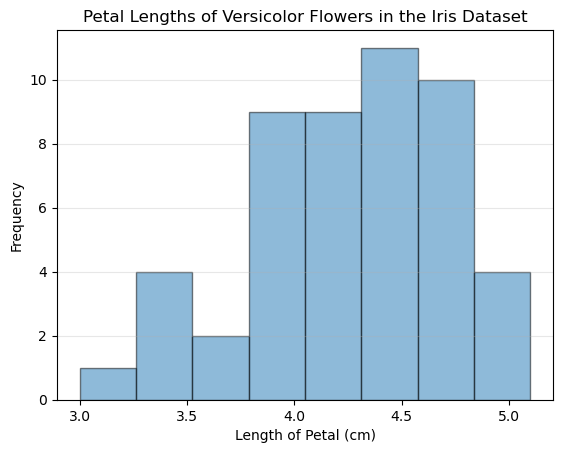

In [ ]:
# I need to find out what my xmin and xmax will be, so I'm going to use the mean and standard deviation of the petal lengths for the versicolor species 
# to calculate the x-axis limits of the histogram plot
fig, ax = plt.subplots()
ax.hist(iris_df["petal_length"][iris_df["class"] == "versicolor"], bins=8, edgecolor="black", alpha=0.5, density=False, label="Versicolor Petal Lengths Histogram")
# Dictating the look of my chart
# legend
#ax.legend(loc="upper right")

# axis titles
ax.set_xlabel("Length of Petal (cm)")
ax.set_ylabel("Frequency")

# chart title
plt.title("Petal Lengths of Versicolor Flowers in the Iris Dataset")

plt.grid(axis="y", alpha=0.3)
plt.show()
#plt.savefig("petal_lengths.png")

In [ ]:
# from the histogram, I can see that the petal lengths for the versicolor species are spread between 4cm and 7cm, 
# so I will superimpose a normal distribution curve on top of the histogram using a min of 4cm and a max of 7cm.

xmin_versicolor = 3 # I've set the minimum x-axis limit to 3, as there are petal lengths shorter than 3cm in the dataset for the versicolor species
xmax_versicolor = 5.5 # I've set the maximum x-axis limit to 5.5, as there are no petal lengths greater than 5.5 in the dataset for the versicolor species
x_versicolor = np.linspace(xmin_versicolor, xmax_versicolor, 100)

# To calculate the normal distribution values for the x values 
# using the mean and standard deviation of the petal lengths
p_versicolor = sp.stats.norm.pdf(x_versicolor, loc=mean_petal_length_versicolor, scale=std_deviation_petal_length_versicolor)
# Scipy's norm.pdf function calculates the probability density function (PDF) of a normal distribution 

# for a given set of x values between xmin and xmax, using the iris' petal length mean (loc), and iris' petal length standard deviation (scale).
print(f"Normal distribution values for the x values: \n {p_versicolor}")

Normal distribution values for the x values: 
 [0.02331707 0.02689218 0.03092599 0.03546232 0.04054679 0.04622656
 0.05254998 0.05956612 0.0673243  0.07587352 0.08526179 0.09553543
 0.1067383  0.11891096 0.13208981 0.14630615 0.16158522 0.1779453
 0.19539669 0.21394084 0.23356943 0.25426356 0.275993   0.29871553
 0.32237649 0.34690833 0.37223046 0.39824918 0.4248579  0.45193743
 0.47935663 0.50697317 0.53463455 0.56217934 0.58943858 0.61623738
 0.64239675 0.66773546 0.69207213 0.71522731 0.7370257  0.75729831
 0.77588463 0.79263479 0.80741147 0.82009189 0.8305694  0.83875506
 0.84457882 0.84799059 0.84896091 0.84748138 0.84356479 0.83724495
 0.82857618 0.81763253 0.80450674 0.78930895 0.77216512 0.75321532
 0.73261182 0.71051705 0.68710151 0.66254154 0.63701717 0.61070991
 0.58380071 0.55646784 0.52888511 0.50122003 0.4736323  0.44627239
 0.41928037 0.39278497 0.36690278 0.34173774 0.31738084 0.29390995
 0.27138989 0.24987273 0.22939813 0.20999391 0.1916767  0.17445273
 0.15831863 0.14

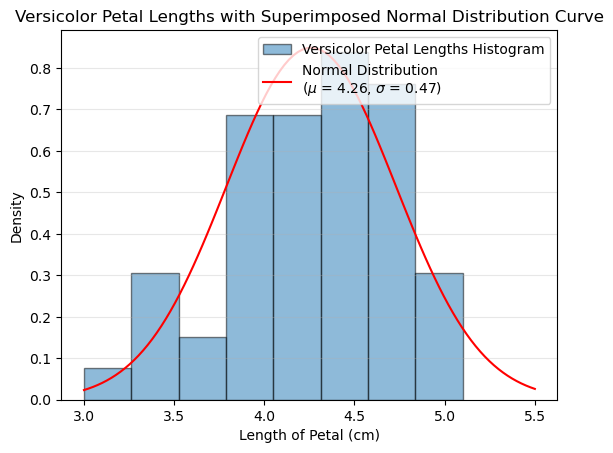

In [49]:
fig, ax = plt.subplots()
ax.hist(iris_df["petal_length"][iris_df["class"] == "versicolor"], bins=8, edgecolor="black", alpha=0.5, density=True , label="Versicolor Petal Lengths Histogram")
# histogram from above except for the normalization.

p_versicolor = (1 / (std_deviation_petal_length_versicolor * np.sqrt(2 * np.pi))) * np.exp(-((x_versicolor - mean_petal_length_versicolor) ** 2) / (2 * std_deviation_petal_length_versicolor**2))
# normal distribution values for the x values using the mean and standard deviation of the petal lengths for the versicolor species

ax.plot(x_versicolor, p_versicolor, color="red", label=f"Normal Distribution \n($\mu$ = {mean_petal_length_versicolor:.2f}, $\sigma$ = {std_deviation_petal_length_versicolor:.2f})")

# legend
ax.legend(loc="upper right")

# axis titles
ax.set_xlabel("Length of Petal (cm)")
ax.set_ylabel("Density")

# chart title
ax.set_title("Versicolor Petal Lengths with Superimposed Normal Distribution Curve")

plt.grid(axis="y", alpha=0.3)
plt.show()
#plt.savefig("petal_lengths.png")

From this chart, the bars of the histogram are very high between say 3.75 and 4.75 centimeters, suggesting that most of the virginica flowers have these petal lengths. In fact, the normal distribution confirms that this is the case, most of the density function is in the middle with only a small amount in the tails.  It does have a wider distribution than the Setosa given it has a standard deviation almost three times that of Setosa.

#### Virginica Petal Lengths

In [50]:
mean_petal_length_virginica = np.mean(iris_df["petal_length"][iris_df["class"] == "virginica"])
# calculate the mean of the petal lengths for the virginica species
std_deviation_petal_length_virginica = np.std(iris_df["petal_length"][iris_df["class"] == "virginica"], ddof=1)
# calculate the standard deviation of the petal lengths for the virginica species

print(f"Mean petal length for Virginica: {round(mean_petal_length_virginica, 2)}")
print(f"Standard deviation of petal length for Virginica: {round(std_deviation_petal_length_virginica, 2)}")

Mean petal length for Virginica: 5.55
Standard deviation of petal length for Virginica: 0.55


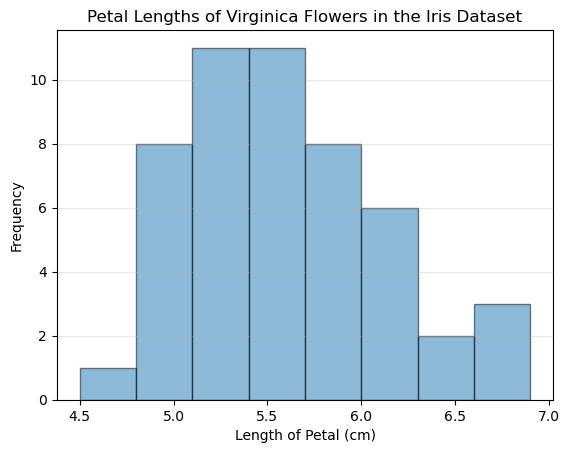

In [51]:
# I need to find out what my xmin and xmax will be, so I'm going to use the mean and standard deviation of the petal lengths for the virginica species 
# to calculate the x-axis limits of the histogram plot
fig, ax = plt.subplots()
ax.hist(iris_df["petal_length"][iris_df["class"] == "virginica"], bins=8, edgecolor="black", alpha=0.5, density=False, label="Virginica Petal Lengths Histogram")
# Dictating the look of my chart
# legend
#ax.legend(loc="upper right")

# axis titles
ax.set_xlabel("Length of Petal (cm)")
ax.set_ylabel("Frequency")

# chart title
plt.title("Petal Lengths of Virginica Flowers in the Iris Dataset")

plt.grid(axis="y", alpha=0.3)
plt.show()
#plt.savefig("petal_lengths.png")

In [56]:
# from the histogram, I can see that the petal lengths for the virginica species are spread between 4cm and 7cm, 
# so I will superimpose a normal distribution curve on top of the histogram using a min of 4cm and a max of 7cm.

xmin_virginica = 4 # I've set the minimum x-axis limit to 4, as there are petal lengths shorter than 4cm in the dataset for the virginica species
xmax_virginica = 7 # I've set the maximum x-axis limit to 7, as there are no petal lengths greater than 7 in the dataset for the virginica species
x_virginica = np.linspace(xmin_virginica, xmax_virginica, 100)

# To calculate the normal distribution values for the x values 
# using the mean and standard deviation of the petal lengths
p_virginica = sp.stats.norm.pdf(x_virginica, loc=mean_petal_length_virginica, scale=std_deviation_petal_length_virginica)
# Scipy's norm.pdf function calculates the probability density function (PDF) of a normal distribution 

# for a given set of x values between xmin and xmax, using the iris' petal length mean (loc), and iris' petal length standard deviation (scale).
print(f"Normal distribution values for the x values: \n {p_virginica}")

Normal distribution values for the x values: 
 [0.01386233 0.01615249 0.01876434 0.02173291 0.02509535 0.02889077
 0.0331601  0.03794575 0.04329135 0.04924133 0.05584048 0.0631334
 0.07116393 0.07997447 0.08960525 0.10009359 0.11147301 0.12377242
 0.1370152  0.15121827 0.16639125 0.18253553 0.19964342 0.21769741
 0.23666947 0.25652038 0.27719935 0.29864361 0.32077826 0.34351628
 0.36675867 0.39039492 0.4143035  0.43835275 0.46240183 0.48630199
 0.50989792 0.53302933 0.55553275 0.57724331 0.59799677 0.61763153
 0.63599069 0.65292416 0.66829069 0.68195979 0.6938136  0.70374859
 0.71167703 0.71752832 0.72125001 0.72280858 0.72218998 0.71939977
 0.71446313 0.7074244  0.69834645 0.68730976 0.67441121 0.65976266
 0.64348936 0.62572815 0.60662556 0.58633578 0.56501864 0.5428375
 0.5199572  0.49654205 0.47275394 0.44875052 0.42468356 0.4006975
 0.37692808 0.35350132 0.33053259 0.3081259  0.28637349 0.2653555
 0.24513994 0.22578274 0.20732806 0.1898087  0.17324665 0.15765373
 0.14303237 0.12937

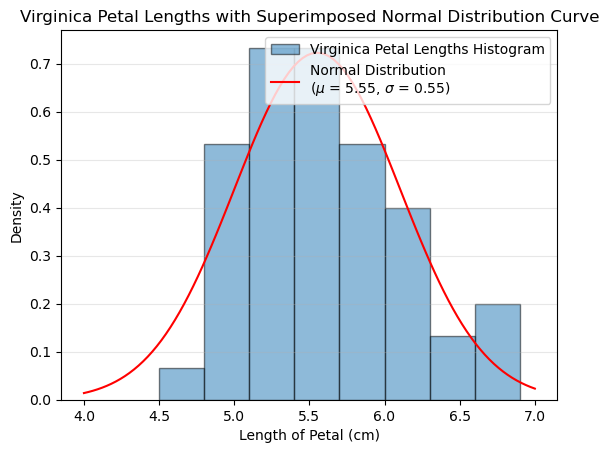

In [57]:
fig, ax = plt.subplots()
ax.hist(iris_df["petal_length"][iris_df["class"] == "virginica"], bins=8, edgecolor="black", alpha=0.5, density=True , label="Virginica Petal Lengths Histogram")
# histogram from above except for the normalization.

p_virginica = (1 / (std_deviation_petal_length_virginica * np.sqrt(2 * np.pi))) * np.exp(-((x_virginica - mean_petal_length_virginica) ** 2) / (2 * std_deviation_petal_length_virginica**2))
# normal distribution values for the x values using the mean and standard deviation of the petal lengths for the virginica species

ax.plot(x_virginica, p_virginica, color="red", label=f"Normal Distribution \n($\mu$ = {mean_petal_length_virginica:.2f}, $\sigma$ = {std_deviation_petal_length_virginica:.2f})")

# legend
ax.legend(loc="upper right")

# axis titles
ax.set_xlabel("Length of Petal (cm)")
ax.set_ylabel("Density")

# chart title
ax.set_title("Virginica Petal Lengths with Superimposed Normal Distribution Curve")

plt.grid(axis="y", alpha=0.3)
plt.show()
#plt.savefig("petal_lengths.png")

From this chart, the bars of the histogram are very high between say 4.75 and 6.25 centimeters, suggesting that most of the virginica flowers have these petal lengths. In fact, the normal distribution confirms that this is the case, most of the density function is in the middle with only a small amount in the tails.  It does however have a wider distribution than the other flower classes, over three times the standard deviation of Setosa, although it has only a slightly bigger standard deviation than versicolor.

#### 4. Reporting the mean and standard deviation for the complete dataset and for each species

Goal: Investigate the distribution of petal_length across all flowers and within species.
Approach: Generate histograms for the full dataset and each species subset. Superimpose normal distribution curves using calculated means and standard deviations. Report descriptive statistics (mean, std) to visually assess normality.

The Iris dataset contains measurements of 150 iris flowers belonging to three species: setosa, versicolor, and virginica. For each flower, the dataset records sepal length, sepal width, petal length, and petal width.

Using the Iris dataset, investigate the distribution of petal_length.

    Plot a histogram showing the petal lengths of all 150 flowers.
    On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.
    Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.
    Report the mean and standard deviation of petal length for the complete dataset and for each species.
    Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.


## Problem 2: Correlation Between Petal Length and Petal Width

Goal: Quantify the linear relationship between petal_length and petal_width.
Approach: Calculate the Pearson correlation coefficient for the pooled dataset and separately per species. Visualize with scatter plots and regression lines to compare global vs. species-specific trends.

Investigate the relationship between petal_length and petal_width in the Iris dataset.

    Calculate the Pearson correlation coefficient between petal length and petal width using all 150 flowers.
    Create an appropriate scatter plot showing the relationship between the two variables, and include a suitable line to help illustrate the relationship.
    Calculate the Pearson correlation coefficient separately for each of the three species.
    Create an appropriate plot showing the relationship between petal length and petal width for each species.
    Report and compare the correlation coefficients.
    Explain what the correlation coefficients tell you about the relationship between petal length and petal width, both for the dataset as a whole and within each species.


## Problem 3: Comparing Species Using t-Tests

 Goal: Determine if significant differences exist in petal dimensions between species pairs.
Approach: Perform independent-samples t-tests (via scipy.stats.ttest_ind) for all species pairs (setosa vs. versicolor, setosa vs. virginica, versicolor vs. virginica) on both petal length and width. Evaluate results against a significance level of α = 0.05 .

Investigate whether the three iris species differ in their petal_length and petal_width.

For each pair of species:

    setosa vs versicolor
    setosa vs virginica
    versicolor vs virginica

perform an independent-samples t-test for:

    petal length,
    petal width.

For each test:

    State the null and alternative hypotheses.
    Calculate the t-statistic and p-value using scipy.stats.
    Use a significance level of α = 0.05 to decide whether to reject the null hypothesis.
    Summarise your results in an appropriate table.
    Explain what the results tell you about differences between the three species.


## Problem 4: Comparing Species Using ANOVA

Goal: Test for differences among all three species simultaneously while controlling the family-wise error rate.
Approach: Conduct one-way ANOVA (via scipy.stats.f_oneway) for petal length and width. Discuss the limitations of pairwise t-testing (increased Type I error probability) and why ANOVA is statistically preferable for multi-group comparisons.

The t-tests in Problem 3 require several separate comparisons between species. Instead, investigate differences in petal length and petal width using one-way analysis of variance (ANOVA).

For each variable:

    State the null and alternative hypotheses for a one-way ANOVA.
    Perform a one-way ANOVA comparing the three species using scipy.stats.
    Report the F-statistic and p-value.
    Use a significance level of α = 0.05 to determine whether there is evidence that the species have different population means.
    Explain what the ANOVA result tells you and what it does not tell you about the individual species.

The t-tests in Problem 3 involved three pairwise comparisons. Explain why performing several separate hypothesis tests can increase the overall probability of making a type I error, and explain how ANOVA addresses this problem by testing the three group means simultaneously.

Finally, compare the conclusions from your t-tests with those from the ANOVA and explain why ANOVA is generally preferable when comparing more than two groups..


## End